In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pickle
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('../data/ds_salaries.csv')
print(df.shape)
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

(607, 12)
   Unnamed: 0  work_year experience_level employment_type  \
0           0       2020               MI              FT   
1           1       2020               SE              FT   
2           2       2020               SE              FT   
3           3       2020               MI              FT   
4           4       2020               SE              FT   

                    job_title  salary salary_currency  salary_in_usd  \
0              Data Scientist   70000             EUR          79833   
1  Machine Learning Scientist  260000             USD         260000   
2           Big Data Engineer   85000             GBP         109024   
3        Product Data Analyst   20000             USD          20000   
4   Machine Learning Engineer  150000             USD         150000   

  employee_residence  remote_ratio company_location company_size  
0                 DE             0               DE            L  
1                 JP             0               JP     

In [7]:
df = df.drop(['Unnamed: 0', 'salary', 'salary_currency'], axis=1)

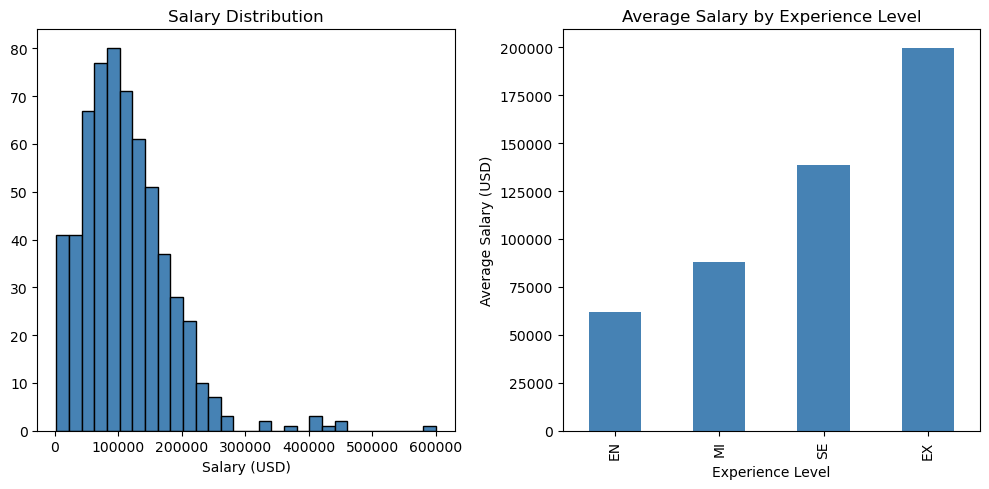

In [9]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(df['salary_in_usd'], bins=30, color='steelblue', edgecolor='black')
plt.title('Salary Distribution')
plt.xlabel('Salary (USD)')

plt.subplot(1, 2, 2)
df.groupby('experience_level')['salary_in_usd'].mean().sort_values().plot(kind='bar', color='steelblue')
plt.title('Average Salary by Experience Level')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary (USD)')
plt.tight_layout()
plt.show()

In [11]:
print("Top 10 Job Titles:")
print(df['job_title'].value_counts().head(10))

print("\nExperience Levels:", df['experience_level'].unique())
print("Employment Types:", df['employment_type'].unique())
print("Company Sizes:", df['company_size'].unique())

Top 10 Job Titles:
job_title
Data Scientist                143
Data Engineer                 132
Data Analyst                   97
Machine Learning Engineer      41
Research Scientist             16
Data Science Manager           12
Data Architect                 11
Big Data Engineer               8
Machine Learning Scientist      8
Principal Data Scientist        7
Name: count, dtype: int64

Experience Levels: ['MI' 'SE' 'EN' 'EX']
Employment Types: ['FT' 'CT' 'PT' 'FL']
Company Sizes: ['L' 'S' 'M']


In [13]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

categorical_cols = ['experience_level', 'employment_type', 
                    'job_title', 'employee_residence', 
                    'company_location', 'company_size']

le = LabelEncoder()
for col in categorical_cols:
    df_model[col] = le.fit_transform(df_model[col])

print("Encoded dataset shape:", df_model.shape)
print(df_model.head())

Encoded dataset shape: (607, 9)
   work_year  experience_level  employment_type  job_title  salary_in_usd  \
0       2020                 2                2         22          79833   
1       2020                 3                2         41         260000   
2       2020                 3                2          7         109024   
3       2020                 2                2         47          20000   
4       2020                 3                2         38         150000   

   employee_residence  remote_ratio  company_location  company_size  
0                  14             0                12             0  
1                  32             0                29             2  
2                  20            50                18             1  
3                  23             0                20             2  
4                  55            50                48             0  


In [15]:
X = df_model.drop('salary_in_usd', axis=1)
y = df_model['salary_in_usd']

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (485, 8)
Test set size: (122, 8)


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    results[name] = {'R2': round(r2, 4), 'RMSE': round(rmse, 2)}
    print(f"{name}: R² = {r2:.4f}, RMSE = ${rmse:,.2f}")

Linear Regression: R² = 0.3180, RMSE = $51,125.49
Random Forest: R² = 0.5543, RMSE = $41,329.93
Gradient Boosting: R² = 0.5511, RMSE = $41,478.82


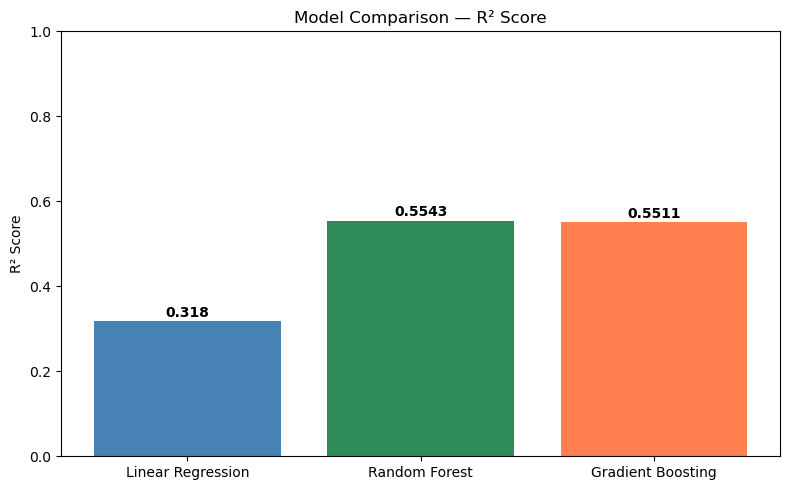

In [19]:
models_names = list(results.keys())
r2_scores = [results[m]['R2'] for m in models_names]

plt.figure(figsize=(8, 5))
bars = plt.bar(models_names, r2_scores, color=['steelblue', 'seagreen', 'coral'])
plt.title('Model Comparison — R² Score')
plt.ylabel('R² Score')
plt.ylim(0, 1)
for bar, score in zip(bars, r2_scores):
    plt.text(bar.get_x() + bar.get_width()/2, 
             bar.get_height() + 0.01, 
             str(score), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

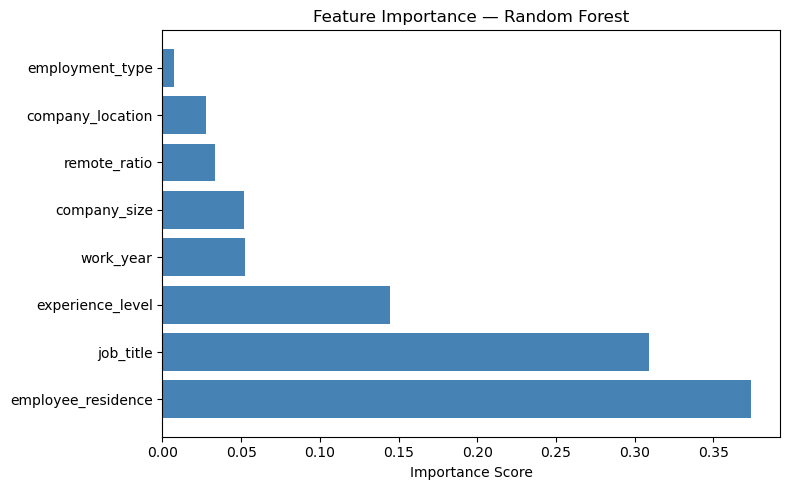

              Feature  Importance
4  employee_residence    0.373601
3           job_title    0.308912
1    experience_level    0.144680
0           work_year    0.052128
7        company_size    0.051720
5        remote_ratio    0.033645
6    company_location    0.027712
2     employment_type    0.007601


In [21]:
rf_model = models["Random Forest"]
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(feature_importance['Feature'], 
         feature_importance['Importance'], 
         color='steelblue')
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print(feature_importance)

In [23]:
import pickle

best_model = models["Random Forest"]

# Save model
with open('../model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

# Save feature columns for Flask API
import json
with open('../features.json', 'w') as f:
    json.dump(list(X.columns), f)

print("✅ Model saved successfully!")
print("Features:", list(X.columns))

✅ Model saved successfully!
Features: ['work_year', 'experience_level', 'employment_type', 'job_title', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']


In [25]:
encoders = {}
categorical_cols = ['experience_level', 'employment_type', 
                    'job_title', 'employee_residence', 
                    'company_location', 'company_size']

# Refit encoders and save them
for col in categorical_cols:
    le = LabelEncoder()
    le.fit(df[col])
    encoders[col] = le

with open('../encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)

print("✅ Encoders saved!")
print("Encoder classes sample:")
print("experience_level:", encoders['experience_level'].classes_)
print("company_size:", encoders['company_size'].classes_)

✅ Encoders saved!
Encoder classes sample:
experience_level: ['EN' 'EX' 'MI' 'SE']
company_size: ['L' 'M' 'S']
